# Part 2 — Image generation (2.3) and evaluation, safety (2.4)
**Colab:** Runtime → GPU (T4 or L4) → Run all. Needs the 512×512 train/test images and the two LoRA adapters that
`p2_train.ipynb` wrote to the local project storage (`outputs/p2_drive/`).

1. **Generate** 20 prompts × seeds {0, 1} × {base, run 1, run 2} = 120 images with one fixed sampler.
   Also one image per test caption for each model (3 × 122), used only for the extended KID below.
2. **Metrics:** KID against the test images (in-domain generations; lower is better), CLIP score (prompt ↔ image),
   LPIPS between the two seeds of each prompt (diversity), NSFW flags, generation time, training GPU-hours.
3. **Final run** choice, **grids** for 8 prompts, **memorization** check, **failure modes**.
4. **Human evaluation** pack: 25 blinded pairs (final run vs base, left/right randomized) for ≥ 3 raters.
5. **Upload** the 120 images to a Hugging Face dataset with prompt, seed and model in the metadata.

**NSFW-flagged images (v4).** The safety checker returns a black image when it flags one. Every flagged image is
generated again with the same seed and the checker off (`gen/flagged_raw/` on Drive); a team member inspected them
(`FLAG_AUDIT_VERDICT`). After that audit, **every model is scored on all 40 / 122 images**, using the checker-off
copy where the checker flagged one, so all three models are compared on the same prompts and seeds. A check below
shows that a checker-off copy is the same sample as the original. The v3 approach (leave flagged images out) is
kept as a second, "filtered" row: it scored the LoRAs on fewer, non-random images (12 vs 20 in-domain for run 2).

Heavy files (images) go to Drive; small results (tables, figures, rater pack) go to the synced `outputs/p2/`.
Images that already exist are not generated again, so Run all is safe to repeat after a disconnect.
The runtime disconnects itself when the run finishes or any cell fails (`AUTO_DISCONNECT`).

In [5]:
# Cell 1 - run information (required)
NOTEBOOK_VERSION = "p2-gen-eval-v4 2026-11-12: all 40/122 images scored (audited checker-off copies for flagged ones); filtered row kept"
from pathlib import Path
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import subprocess, sys, random, numpy as np, torch
IN_COLAB = os.path.exists("/var/colab/hostname")
LAB2 = os.environ.get("P2_ROOT", str(Path.cwd().parent))
AUTO_DISCONNECT = True   # release the GPU when the run ends or any cell errors (Colab only)
if IN_COLAB:
    from google.colab import drive, runtime
    drive.mount("/content/drive")
    os.chdir(f"{LAB2}/notebooks")
    def _disconnect_on_error(shell, etype, evalue, tb, tb_offset=None):
        shell.showtraceback((etype, evalue, tb), tb_offset=tb_offset)
        if AUTO_DISCONNECT:
            print("Stopped - disconnecting the GPU runtime."); runtime.unassign()
    get_ipython().set_custom_exc((Exception,), _disconnect_on_error)
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"version": NOTEBOOK_VERSION, "commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'version': 'p2-gen-eval-v4 2026-11-12: all 40/122 images scored (audited checker-off copies for flagged ones); filtered row kept', 'commit': '', 'python': '3.12.10', 'torch': '2.11.0+cu128', 'gpu': 'NVIDIA GeForce RTX 5090', 'seed': 266}


In [6]:
# Installs: Colab has none of these preinstalled. KID = torchmetrics + torch-fidelity (Inception weights), diversity = lpips
import importlib.util
_need = {"torchmetrics": "torchmetrics", "torch_fidelity": "torch-fidelity", "lpips": "lpips", "diffusers": "diffusers", "peft": "peft"}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
    importlib.invalidate_caches(); print("Installed:", _missing)
if importlib.util.find_spec("torchao") is not None:      # same Colab torchao clash as in p2_train.ipynb
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    importlib.invalidate_caches()
import diffusers, peft, transformers, torchmetrics, lpips
print({"diffusers": diffusers.__version__, "peft": peft.__version__, "transformers": transformers.__version__,
       "torchmetrics": torchmetrics.__version__, "lpips": getattr(lpips, "__version__", "?")})

W1117 18:50:50.641000 46308 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


{'diffusers': '0.42.1', 'peft': '0.21.2', 'transformers': '5.22.1', 'torchmetrics': '1.9.0', 'lpips': '?'}


In [7]:
# Paths, models and sampler settings (the same for every model and image)
import json, hashlib, time, base64, io, re, csv
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path(os.environ.get("P2_ROOT", str(Path.cwd().parent))).resolve()
EVAL_DIR = PROJECT_ROOT / "eval"; OUT_DIR = PROJECT_ROOT / "outputs" / "p2"; OUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE = Path(os.environ.get("P2_DATA_ROOT", str(PROJECT_ROOT / "outputs" / "p2_drive")))
TRAIN_DIR, TEST_DIR, RUNS_ROOT = DRIVE / "data" / "train", DRIVE / "data" / "test", DRIVE / "runs"
GEN_MAIN, GEN_KID = DRIVE / "gen" / "main", DRIVE / "gen" / "kid_test_captions"
for d in (GEN_MAIN, GEN_KID): d.mkdir(parents=True, exist_ok=True)

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
MODELS = {"base": None,                                  # name -> adapter folder on Drive (None = base model)
          "run1_lora_r4": RUNS_ROOT / "run1_lora_r4_s5000",
          "run2_lora_r32": RUNS_ROOT / "run2_lora_r32_s5000"}
SAMPLER = {"scheduler": "DPMSolverMultistepScheduler", "num_inference_steps": 30, "guidance_scale": 7.5,
           "height": 512, "width": 512, "lora_scale": 1.0, "safety_checker": "on"}
SEEDS = [0, 1]
EXTENDED_KID = True        # also generate one image per test caption per model (3 x 122) for a steadier KID
FINAL_RUN = "auto"         # "auto" = the LoRA run with the lower test-caption KID (in-domain KID if EXTENDED_KID is off)
CLIP_MODEL = "openai/clip-vit-large-patch14"
assert torch.cuda.is_available(), "This notebook needs a GPU runtime"
for name, d in MODELS.items():
    if d is not None:
        assert (d / "pytorch_lora_weights.safetensors").exists(), f"{name}: adapter missing in {d}"
print({"drive": str(DRIVE), "models": {k: str(v) if v else "base" for k, v in MODELS.items()}, "sampler": SAMPLER})

{'drive': 'C:\\Users\\centhur1.ADS-A51-840-12\\Desktop\\LAB2\\DATA266_Lab2_Part2_VSCode\\outputs\\p2_drive', 'models': {'base': 'base', 'run1_lora_r4': 'C:\\Users\\centhur1.ADS-A51-840-12\\Desktop\\LAB2\\DATA266_Lab2_Part2_VSCode\\outputs\\p2_drive\\runs\\run1_lora_r4_s5000', 'run2_lora_r32': 'C:\\Users\\centhur1.ADS-A51-840-12\\Desktop\\LAB2\\DATA266_Lab2_Part2_VSCode\\outputs\\p2_drive\\runs\\run2_lora_r32_s5000'}, 'sampler': {'scheduler': 'DPMSolverMultistepScheduler', 'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512, 'lora_scale': 1.0, 'safety_checker': 'on'}}


In [8]:
# The 20 prompts: checked against the hash recorded before training (eval/p2_lineage.json)
def rows_sha256(df):
    rows = sorted([str(r.id).strip(), str(r.type).strip(), str(r.prompt).strip()] for r in df.itertuples())
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()
prompts = pd.read_csv(EVAL_DIR / "p2_prompts.csv")
lineage = json.loads((EVAL_DIR / "p2_lineage.json").read_text())
assert rows_sha256(prompts) == lineage["all_prompts"]["sha256"], "prompts differ from the ones hashed before training"
print("Prompts match the hash recorded at", lineage["all_prompts"]["hashed_at_utc"])
print(prompts["type"].value_counts().to_dict())

def read_meta(folder):
    return [json.loads(l) for l in open(folder / "metadata.jsonl")]
test_meta, train_meta = read_meta(TEST_DIR), read_meta(TRAIN_DIR)
print({"test_images": len(test_meta), "train_images": len(train_meta)})

Prompts match the hash recorded at 2026-11-17T01:35:15+00:00
{'in_domain': 10, 'out_of_domain': 5, 'compositional': 5}
{'test_images': 122, 'train_images': 1099}


## 2.3 Generate 120 images: 20 prompts × seeds {0, 1} × {base, run 1, run 2}
Same scheduler, steps, guidance, size and seeds for all three models. The LoRA is the only difference.
The Stable Diffusion safety checker stays on and its NSFW flag is recorded per image (a flagged image comes back black).

In [9]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda")
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

def use_model(name):
    pipe.unload_lora_weights()
    if MODELS[name] is not None:
        pipe.load_lora_weights(str(MODELS[name]), weight_name="pytorch_lora_weights.safetensors")

def generate(prompt, seed):
    t0 = time.time()
    out = pipe(prompt, num_inference_steps=SAMPLER["num_inference_steps"], guidance_scale=SAMPLER["guidance_scale"],
               height=SAMPLER["height"], width=SAMPLER["width"],
               generator=torch.Generator("cuda").manual_seed(seed),
               cross_attention_kwargs={"scale": SAMPLER["lora_scale"]})
    nsfw = bool(out.nsfw_content_detected[0]) if out.nsfw_content_detected is not None else False
    return out.images[0], nsfw, time.time() - t0

def run_jobs(jobs, folder, log_name):
    """jobs: dicts with model, file, prompt, seed (+ extra columns). Skips images that already exist."""
    log_file = folder / log_name
    done = {r["file"]: r for r in (json.loads(l) for l in open(log_file))} if log_file.exists() else {}
    todo = [j for j in jobs if not ((folder / j["file"]).exists() and j["file"] in done)]
    print(f"{len(jobs) - len(todo)} of {len(jobs)} images already exist; generating {len(todo)}.")
    for name in MODELS:
        mine = [j for j in todo if j["model"] == name]
        if not mine: continue
        use_model(name); t_model = time.time()
        with open(log_file, "a") as lf:
            for k, j in enumerate(mine):
                img, nsfw, secs = generate(j["prompt"], j["seed"])
                img.save(folder / j["file"])
                rec = {**j, "nsfw_flag": nsfw, "seconds": round(secs, 2)}
                lf.write(json.dumps(rec) + "\n"); done[j["file"]] = rec
        print(f"  {name}: {len(mine)} images in {(time.time() - t_model) / 60:.1f} min")
    return pd.DataFrame([done[j["file"]] for j in jobs])

main_jobs = [{"model": m, "id": r.id, "type": r.type, "prompt": r.prompt, "seed": s,
              "file": f"{m}__{r.id}__seed{s}.png"} for m in MODELS for r in prompts.itertuples() for s in SEEDS]
gen = run_jobs(main_jobs, GEN_MAIN, "generation_log.jsonl")
gen.to_csv(OUT_DIR / "generations.csv", index=False)
print(gen.groupby("model").agg(images=("file", "size"), nsfw_flags=("nsfw_flag", "sum"),
                               sec_per_image=("seconds", "mean")).round(2))

c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\torch\nn\modules\module.py:1370: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  return t.to(


0 of 120 images already exist; generating 120.


... (2 outputs left out)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

  run1_lora_r4: 40 images in 0.7 min


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A blac

  run2_lora_r32: 40 images in 0.7 min
               images  nsfw_flags  sec_per_image
model                                           
base               40           0           0.77
run1_lora_r4       40          11           1.05
run2_lora_r32      40           5           1.03


In [10]:
# Extended KID set: one image per test caption for each model (seed = position in the test set)
if EXTENDED_KID:
    kid_jobs = [{"model": m, "test_file": t["file_name"], "prompt": t["text"], "seed": k,
                 "file": f"{m}__test{k:03d}.png"} for m in MODELS for k, t in enumerate(test_meta)]
    gen_kid = run_jobs(kid_jobs, GEN_KID, "generation_log.jsonl")
    print(gen_kid.groupby("model").agg(images=("file", "size"), nsfw_flags=("nsfw_flag", "sum")))

0 of 366 images already exist; generating 366.


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  base: 122 images in 1.5 min


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

  run1_lora_r4: 122 images in 2.1 min


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

  run2_lora_r32: 122 images in 2.2 min
               images  nsfw_flags
model                            
base              122           0
run1_lora_r4      122          44
run2_lora_r32     122          40


### NSFW flags: audit of the flagged images
The safety checker replaces a flagged image with a black one. A black image would distort every metric (KID, CLIP
score, LPIPS, the edge-bar count). The flag rate itself is a C4 safety result.

1. Each flagged image is generated again with the same seed and the checker off, into `gen/flagged_raw/` (Drive).
2. A team member inspected the 14 flagged images of the 120-image set and recorded the verdict below. Only
   because they are all false positives are the checker-off copies used in the metrics, figures and upload.
3. **Same-sample check:** 3 non-flagged images per LoRA are generated again with the checker off and compared with
   the stored files. The checker only replaces the output after sampling, so the copies must match.
4. The safety checker is run again on the checker-off copies: they must be flagged again (same images it rejected).

In [11]:
FLAG_AUDIT_VERDICT = ("14 of 14 flagged images in the 120-image set inspected by the team: clothed characters "
                      "(hoodies, vests, outfits, close-up faces) and two abstract 'demon' creatures; no nudity or "
                      "gore. All false positives.")
RAW_DIR = DRIVE / "gen" / "flagged_raw"; RAW_DIR.mkdir(parents=True, exist_ok=True)
flagged = pd.concat([gen.assign(set="main"), gen_kid.assign(set="kid_test_captions")] if EXTENDED_KID else [gen.assign(set="main")])
flagged = flagged[flagged.nsfw_flag]
checker = pipe.safety_checker
try:
    pipe.safety_checker = None
    for name in MODELS:
        mine = flagged[(flagged.model == name) & ~flagged.file.map(lambda f: (RAW_DIR / f).exists())]
        if mine.empty: continue
        use_model(name)
        for r in mine.itertuples():
            generate(r.prompt, int(r.seed))[0].save(RAW_DIR / r.file)
    # Same-sample check: non-flagged images generated again with the checker off vs the stored files
    same_rows = []
    for name in [m for m in MODELS if MODELS[m] is not None]:
        use_model(name)
        for r in gen[(gen.model == name) & ~gen.nsfw_flag].head(3).itertuples():
            a = np.asarray(generate(r.prompt, int(r.seed))[0], dtype=np.int16)
            b = np.asarray(Image.open(GEN_MAIN / r.file).convert("RGB"), dtype=np.int16)
            same_rows.append({"model": name, "file": r.file, "mean_abs_diff_0_255": round(float(np.abs(a - b).mean()), 3),
                              "max_abs_diff_0_255": int(np.abs(a - b).max())})
finally:
    pipe.safety_checker = checker
same = pd.DataFrame(same_rows); same.to_csv(OUT_DIR / "same_sample_check.csv", index=False)
print("Checker-off copy vs stored image (0-255 scale):"); print(same.to_string(index=False))
assert same.mean_abs_diff_0_255.max() < 3.0, "checker-off copies are not the same samples - do not use them (use the GPU type of the first run: L4)"

# The checker must flag the checker-off copies again (they are the images it rejected)
@torch.no_grad()
def checker_flags(paths):
    arr = np.stack([np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) / 255 for p in paths])
    return list(pipe.run_safety_checker(arr, "cuda", torch.float16)[1])
main_flagged = flagged[flagged.set == "main"]
reflag = checker_flags([RAW_DIR / f for f in main_flagged.file]) if len(main_flagged) else []
print(f"Checker on the checker-off copies: {sum(reflag)} of {len(reflag)} flagged again")
flag_summary = flagged.groupby(["set", "model"]).size().rename("flagged").reset_index()
flag_summary.to_csv(OUT_DIR / "nsfw_flags.csv", index=False)
print(flag_summary.to_string(index=False) if len(flagged) else "No images were flagged.")
for r in flagged[flagged.set == "main"].itertuples(): print(f"  {r.model} {r.id} seed {r.seed}: {r.prompt}")
print(f"{len(flagged)} flagged images re-generated without the checker in {RAW_DIR} (Drive only).")
print("Audit verdict:", FLAG_AUDIT_VERDICT or "NOT RECORDED YET - look at the images and set FLAG_AUDIT_VERDICT")
assert FLAG_AUDIT_VERDICT, "record the audit verdict before the checker-off copies are used"
(OUT_DIR / "nsfw_audit.json").write_text(json.dumps({"flagged_main": int(gen.nsfw_flag.sum()),
    "flagged_kid_set": int(gen_kid.nsfw_flag.sum()) if EXTENDED_KID else None,
    "flagged_main_by_model": gen.groupby("model").nsfw_flag.sum().astype(int).to_dict(),
    "flagged_kid_set_by_model": gen_kid.groupby("model").nsfw_flag.sum().astype(int).to_dict() if EXTENDED_KID else None,
    "verdict": FLAG_AUDIT_VERDICT, "same_sample_max_mean_abs_diff": float(same.mean_abs_diff_0_255.max()),
    "checker_off_copies_flagged_again": f"{sum(reflag)}/{len(reflag)}"}, indent=1))
del pipe; torch.cuda.empty_cache()

# Which file each row is scored with: the stored image, or the audited checker-off copy if the checker flagged it
def src_path(folder, r):
    return RAW_DIR / r.file if r.nsfw_flag else folder / r.file
gen["path"] = [src_path(GEN_MAIN, r) for r in gen.itertuples()]
gen["image_source"] = np.where(gen.nsfw_flag, "checker_off_audited", "pipeline")
if EXTENDED_KID:
    gen_kid["path"] = [src_path(GEN_KID, r) for r in gen_kid.itertuples()]
assert all(p.exists() for p in gen.path) and (not EXTENDED_KID or all(p.exists() for p in gen_kid.path))
gen.drop(columns="path").to_csv(OUT_DIR / "generations.csv", index=False)
ok = gen[~gen.nsfw_flag]                                   # "filtered" sensitivity row only
ok_kid = gen_kid[~gen_kid.nsfw_flag] if EXTENDED_KID else None

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected:

Checker-off copy vs stored image (0-255 scale):
        model                          file  mean_abs_diff_0_255  max_abs_diff_0_255
 run1_lora_r4  run1_lora_r4__p01__seed0.png                  0.0                   0
 run1_lora_r4  run1_lora_r4__p01__seed1.png                  0.0                   0
 run1_lora_r4  run1_lora_r4__p02__seed1.png                  0.0                   0
run2_lora_r32 run2_lora_r32__p01__seed0.png                  0.0                   0
run2_lora_r32 run2_lora_r32__p01__seed1.png                  0.0                   0
run2_lora_r32 run2_lora_r32__p02__seed0.png                  0.0                   0


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Checker on the checker-off copies: 16 of 16 flagged again
              set         model  flagged
kid_test_captions  run1_lora_r4       44
kid_test_captions run2_lora_r32       40
             main  run1_lora_r4       11
             main run2_lora_r32        5
  run1_lora_r4 p02 seed 0: a demon with a gun in his hand
  run1_lora_r4 p04 seed 0: a man in a black shirt and a black vest
  run1_lora_r4 p04 seed 1: a man in a black shirt and a black vest
  run1_lora_r4 p05 seed 0: a man in a purple outfit standing in front of trees
  run1_lora_r4 p06 seed 0: a man in a red and yellow outfit
  run1_lora_r4 p06 seed 1: a man in a red and yellow outfit
  run1_lora_r4 p07 seed 0: a man in a white hoodie looking at the camera
  run1_lora_r4 p07 seed 1: a man in a white hoodie looking at the camera
  run1_lora_r4 p08 seed 0: a man with black hair and a hoodie
  run1_lora_r4 p08 seed 1: a man with black hair and a hoodie
  run1_lora_r4 p17 seed 0: a girl with pink hair holding a green umbrella ne

## 2.4 Metrics
- **KID** (Kernel Inception Distance, lower is better) between a model's in-domain generations and the 122 test
  images. The required version uses the 20 in-domain images per model (10 prompts × 2 seeds), so it is computed
  on 100 random subsets of 20 and is noisy. The extended version uses 122 generations per model (one per test
  caption) with subsets of 100.
- **CLIP score** = 100 × max(cosine(image, prompt), 0) with CLIP ViT-L/14, per image, averaged.
- **LPIPS diversity** = average LPIPS (AlexNet) distance between the seed-0 and seed-1 image of each prompt.

Every metric is computed twice: on **all images** (primary; flagged images as their audited checker-off copy) and
**filtered** (flagged images left out, as in v3). Only the primary numbers compare the models on the same prompts.

In [12]:
from torchmetrics.image.kid import KernelInceptionDistance
def load_u8(paths):
    return torch.from_numpy(np.stack([np.asarray(Image.open(p).convert("RGB")) for p in paths])).permute(0, 3, 1, 2)

def kid(gen_paths, ref_u8, subset_size):
    torch.manual_seed(SEED)
    m = KernelInceptionDistance(subsets=100, subset_size=subset_size, normalize=False).to("cuda")
    for i in range(0, len(ref_u8), 32): m.update(ref_u8[i:i + 32].cuda(), real=True)
    g = load_u8(gen_paths)
    for i in range(0, len(g), 32): m.update(g[i:i + 32].cuda(), real=False)
    mean, std = m.compute(); return float(mean), float(std)

test_u8 = load_u8([TEST_DIR / t["file_name"] for t in test_meta])
def kid_block(main_df, kid_df):
    """KID for each model; main_df / kid_df rows carry the image path to score."""
    out, n = {}, {}
    for name in MODELS:
        ind = main_df[(main_df.model == name) & (main_df.type == "in_domain")]
        out[name] = {"kid_in_domain_20": kid(list(ind.path), test_u8, subset_size=len(ind))}
        n[name] = {"in_domain": len(ind)}
        if EXTENDED_KID:
            kk = kid_df[kid_df.model == name]
            out[name]["kid_test_captions_122"] = kid(list(kk.path), test_u8, min(100, len(kk)))
            n[name]["test_captions"] = len(kk)
    return out, n
KID, KID_N = kid_block(gen, gen_kid if EXTENDED_KID else None)            # primary: all images
KID_F, KID_FN = kid_block(ok, ok_kid)                                     # filtered: flagged images left out
for label, K, N in [("ALL IMAGES", KID, KID_N), ("FILTERED (flagged left out)", KID_F, KID_FN)]:
    print(label)
    for name, v in K.items():
        print(" ", name, {k: f"{m * 1000:.1f} ± {s * 1000:.1f} (x1e-3)" for k, (m, s) in v.items()}, "images used:", N[name])

c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\centhur1.ADS-A51-840-12/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 56.2MB/s]


ALL IMAGES
  base {'kid_in_domain_20': '135.0 ± 12.3 (x1e-3)', 'kid_test_captions_122': '121.9 ± 3.3 (x1e-3)'} images used: {'in_domain': 20, 'test_captions': 122}
  run1_lora_r4 {'kid_in_domain_20': '27.2 ± 7.0 (x1e-3)', 'kid_test_captions_122': '17.9 ± 1.7 (x1e-3)'} images used: {'in_domain': 20, 'test_captions': 122}
  run2_lora_r32 {'kid_in_domain_20': '16.6 ± 5.8 (x1e-3)', 'kid_test_captions_122': '6.4 ± 0.8 (x1e-3)'} images used: {'in_domain': 20, 'test_captions': 122}
FILTERED (flagged left out)
  base {'kid_in_domain_20': '135.0 ± 12.3 (x1e-3)', 'kid_test_captions_122': '121.9 ± 3.3 (x1e-3)'} images used: {'in_domain': 20, 'test_captions': 122}
  run1_lora_r4 {'kid_in_domain_20': '34.1 ± 12.4 (x1e-3)', 'kid_test_captions_122': '23.1 ± 2.5 (x1e-3)'} images used: {'in_domain': 10, 'test_captions': 78}
  run2_lora_r32 {'kid_in_domain_20': '24.7 ± 8.9 (x1e-3)', 'kid_test_captions_122': '5.8 ± 0.8 (x1e-3)'} images used: {'in_domain': 16, 'test_captions': 82}


In [13]:
# CLIP score per image (prompt <-> image) and CLIP image embeddings, reused for the memorization check
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained(CLIP_MODEL, torch_dtype=torch.float16).to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_MODEL)

def _emb(x, kind):
    if torch.is_tensor(x): return x
    for attr in (f"{kind}_embeds", "pooler_output"):
        if getattr(x, attr, None) is not None: return getattr(x, attr)
    raise TypeError(type(x))

@torch.no_grad()
def image_emb(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        px = clip_proc(images=[Image.open(p).convert("RGB") for p in paths[i:i + bs]], return_tensors="pt")["pixel_values"]
        e = _emb(clip.get_image_features(pixel_values=px.to("cuda", torch.float16)), "image")
        out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def text_emb(texts):
    tok = clip_proc(text=list(texts), return_tensors="pt", padding=True, truncation=True, max_length=77)
    e = _emb(clip.get_text_features(input_ids=tok["input_ids"].to("cuda"), attention_mask=tok["attention_mask"].to("cuda")), "text")
    return torch.nn.functional.normalize(e.float(), dim=-1).cpu()

gen_img_emb = image_emb(list(gen.path))
gen["clip_score"] = (100 * (gen_img_emb * text_emb(gen.prompt)).sum(-1).clamp(min=0)).numpy()
ok = gen[~gen.nsfw_flag]
clip_table = gen.pivot_table(index="model", columns="type", values="clip_score", aggfunc="mean")
clip_table["all"] = gen.groupby("model")["clip_score"].mean()
clip_f = ok.groupby("model")["clip_score"].mean()       # filtered row
print("CLIP score, all images:"); print(clip_table.reindex(list(MODELS)).round(2))
print("CLIP score (all prompt types), filtered:", clip_f.round(2).to_dict())

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\centhur1.ADS-A51-840-12\.cache\huggingface\hub\models--openai--clip-vit-large-patch14. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\centhur1.ADS-A51-840-12\Desktop\LA

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP score, all images:
type           compositional  in_domain  out_of_domain    all
model                                                        
base               28.430000  26.120001      28.879999  27.39
run1_lora_r4       26.459999  23.570000      29.840000  25.86
run2_lora_r32      27.299999  22.900000      29.350000  25.61
CLIP score (all prompt types), filtered: {'base': 27.39, 'run1_lora_r4': 27.21, 'run2_lora_r32': 25.85}


In [14]:
# LPIPS between the two seeds of each prompt (higher = more diverse)
lp = lpips.LPIPS(net="alex", verbose=False).to("cuda")
def to_lpips(p): return (torch.from_numpy(np.asarray(Image.open(p).convert("RGB"))).permute(2, 0, 1).float() / 127.5 - 1)[None].cuda()
rows = []
with torch.no_grad():
    for (name, pid), g in gen.groupby(["model", "id"]):
        a, b = (g[g.seed == s].path.iloc[0] for s in SEEDS)
        rows.append({"model": name, "id": pid, "type": g.type.iloc[0], "has_flag": bool(g.nsfw_flag.any()),
                     "lpips": float(lp(to_lpips(a), to_lpips(b)))})
lpips_df = pd.DataFrame(rows); lpips_df.to_csv(OUT_DIR / "lpips_per_prompt.csv", index=False)
lpips_table = lpips_df.pivot_table(index="model", columns="type", values="lpips", aggfunc="mean")
lpips_table["all"] = lpips_df.groupby("model")["lpips"].mean()
lpips_f = lpips_df[~lpips_df.has_flag].groupby("model")["lpips"].mean()   # filtered row
print("LPIPS, all prompts:"); print(lpips_table.reindex(list(MODELS)).round(3))
print("LPIPS (all), filtered:", lpips_f.round(3).to_dict())

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\centhur1.ADS-A51-840-12/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth


c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 233M/233M [00:02<00:00, 115MB/s] 
C:\Users\centhur1.ADS-A51-840-12\AppData\Local\Temp\ipykernel_46308\4224308572.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this t

LPIPS, all prompts:
type           compositional  in_domain  out_of_domain    all
model                                                        
base                   0.847      0.790          0.749  0.794
run1_lora_r4           0.788      0.770          0.741  0.767
run2_lora_r32          0.785      0.738          0.722  0.746
LPIPS (all), filtered: {'base': 0.794, 'run1_lora_r4': 0.762, 'run2_lora_r32': 0.74}


## Results table: base vs run 1 vs run 2

In [15]:
train_meta_runs = {}
for name, d in MODELS.items():
    f = (d / "run_meta.json") if d else None
    train_meta_runs[name] = json.loads(f.read_text()) if f and f.exists() else {}
results = []
for name in MODELS:
    g, tm = gen[gen.model == name], train_meta_runs[name]
    row = {"model": name,
           "kid_in_domain_x1e3": round(KID[name]["kid_in_domain_20"][0] * 1000, 2),
           "kid_in_domain_std_x1e3": round(KID[name]["kid_in_domain_20"][1] * 1000, 2)}
    if EXTENDED_KID:
        row.update(kid_test_captions_x1e3=round(KID[name]["kid_test_captions_122"][0] * 1000, 2),
                   kid_test_captions_std_x1e3=round(KID[name]["kid_test_captions_122"][1] * 1000, 2))
    row.update({f"clip_{t}": round(float(clip_table.loc[name, t]), 2) for t in ["in_domain", "out_of_domain", "compositional", "all"]})
    row.update({"lpips_all": round(float(lpips_table.loc[name, "all"]), 3), "images_scored": len(g),
                "nsfw_flags_main": int(g.nsfw_flag.sum()),
                "nsfw_flag_rate_test_captions": round(float(gen_kid[gen_kid.model == name].nsfw_flag.mean()), 3) if EXTENDED_KID else None,
                # filtered sensitivity row (v3 method): flagged images left out
                "f_kid_in_domain_x1e3": round(KID_F[name]["kid_in_domain_20"][0] * 1000, 2),
                "f_kid_test_captions_x1e3": round(KID_F[name]["kid_test_captions_122"][0] * 1000, 2) if EXTENDED_KID else None,
                "f_clip_all": round(float(clip_f[name]), 2), "f_lpips_all": round(float(lpips_f.get(name, np.nan)), 3),
                "f_images_scored": int((~g.nsfw_flag).sum()),
                "sec_per_image_median": round(float(g.seconds.median()), 2),
                "train_gpu_hours": round(tm["train_seconds"] / 3600, 3) if tm else 0.0,
                "train_peak_gpu_gib": round(tm.get("peak_loop_gpu_mem_mib", 0) / 1024, 2) if tm else None,
                "trainable_params": tm.get("trainable_params", 0)})
    results.append(row)
results = pd.DataFrame(results).set_index("model")
results.to_csv(OUT_DIR / "results_table.csv")
pd.set_option("display.width", 200); print(results.T.to_string())

model                            base  run1_lora_r4  run2_lora_r32
kid_in_domain_x1e3            134.950        27.230         16.600
kid_in_domain_std_x1e3         12.340         6.960          5.840
kid_test_captions_x1e3        121.920        17.880          6.370
kid_test_captions_std_x1e3      3.290         1.720          0.810
clip_in_domain                 26.120        23.570         22.900
clip_out_of_domain             28.880        29.840         29.350
clip_compositional             28.430        26.460         27.300
clip_all                       27.390        25.860         25.610
lpips_all                       0.794         0.767          0.746
images_scored                  40.000        40.000         40.000
nsfw_flags_main                 0.000        11.000          5.000
nsfw_flag_rate_test_captions    0.000         0.361          0.328
f_kid_in_domain_x1e3          134.950        34.140         24.690
f_kid_test_captions_x1e3      121.920        23.080          5

In [16]:
# Final run: the LoRA run with the lower in-domain KID unless FINAL_RUN names one
loras = [m for m in MODELS if MODELS[m] is not None]
if FINAL_RUN == "auto":
    key = "kid_test_captions_x1e3" if EXTENDED_KID else "kid_in_domain_x1e3"
    FINAL_RUN, rule = min(loras, key=lambda m: results.loc[m, key]), f"auto: lower {key}"
    print(f"FINAL_RUN = {FINAL_RUN} ({rule}). Check this against the grids, CLIP score and the human evaluation.")
else:
    rule = "set by hand"; print("FINAL_RUN set by hand:", FINAL_RUN)
assert FINAL_RUN in loras, FINAL_RUN
(OUT_DIR / "final_run.json").write_text(json.dumps({"final_run": FINAL_RUN, "rule": rule}, indent=1))

FINAL_RUN = run2_lora_r32 (auto: lower kid_test_captions_x1e3). Check this against the grids, CLIP score and the human evaluation.


80

## 2.3 Side-by-side grids: 8 prompts, seed 0
The 8 prompts are fixed by rule, not picked after looking: the first 3 in-domain, the first 2 out-of-domain and
the first 3 compositional prompts in `eval/p2_prompts.csv`.

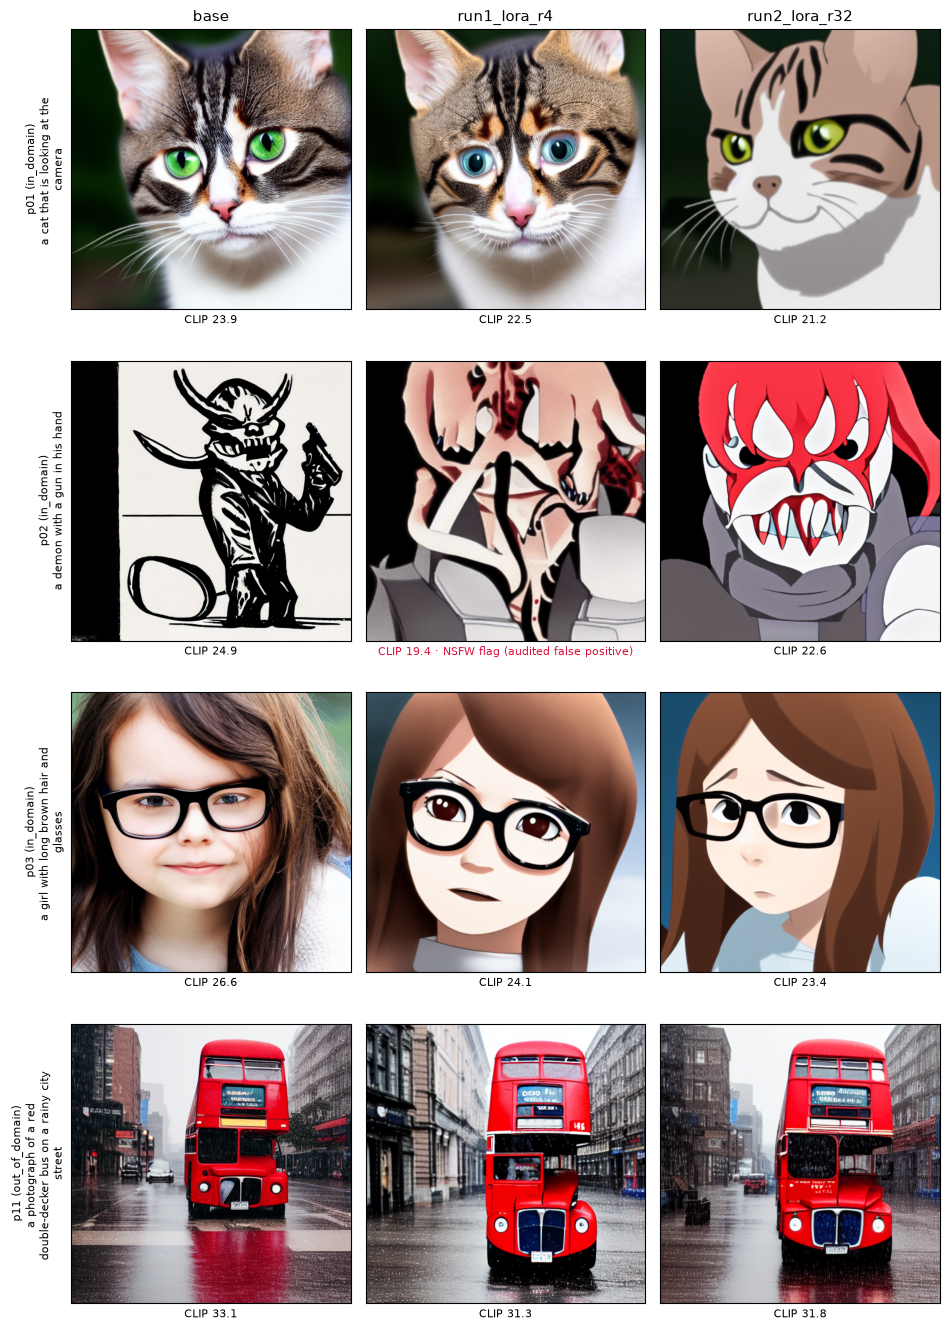

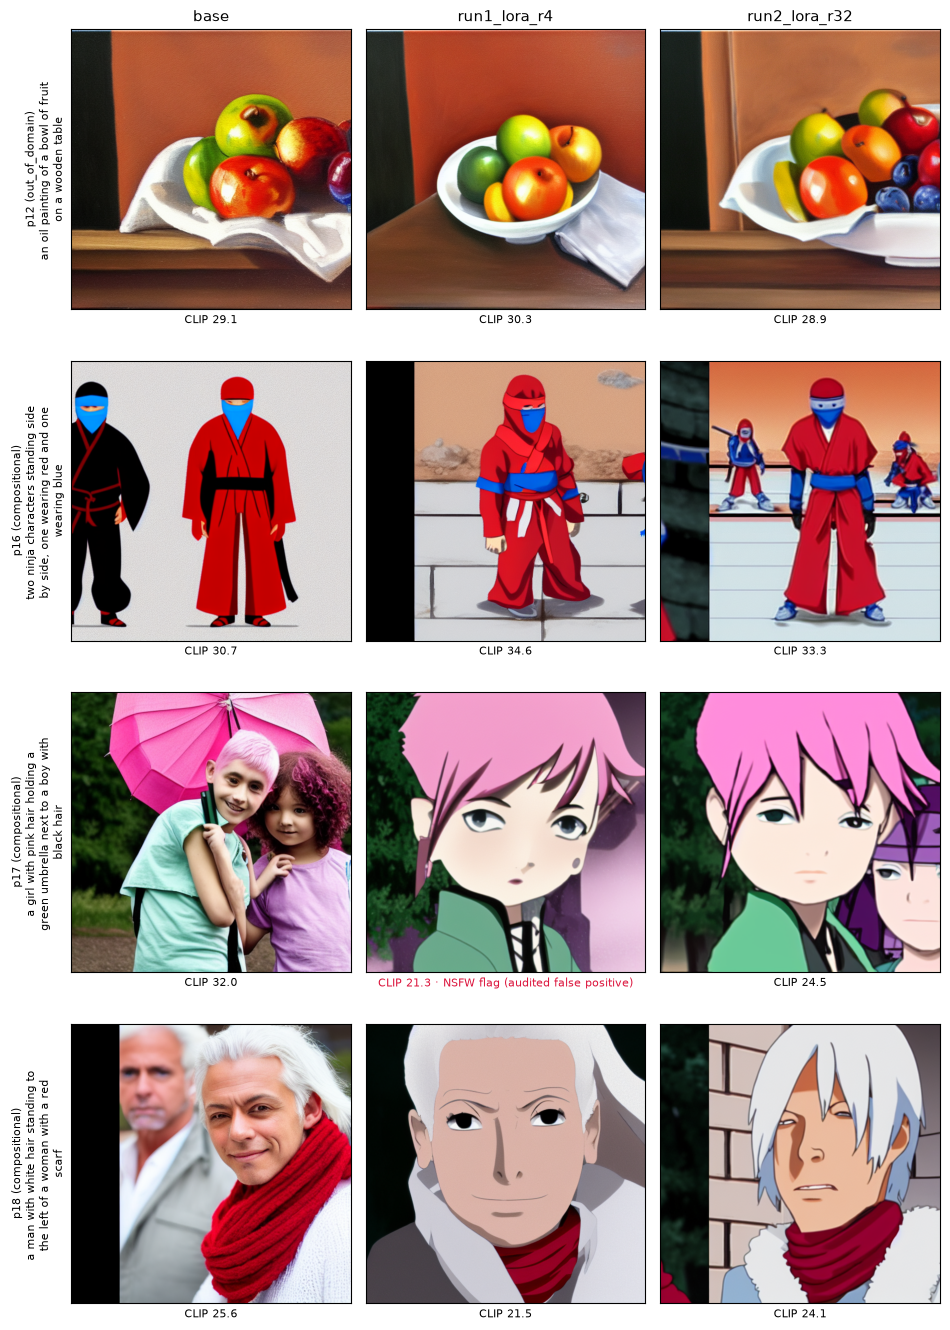

In [17]:
grid_ids = (list(prompts[prompts.type == "in_domain"].id[:3]) + list(prompts[prompts.type == "out_of_domain"].id[:2])
            + list(prompts[prompts.type == "compositional"].id[:3]))
def show_grid(ids, fname, seed=0):
    fig, axes = plt.subplots(len(ids), len(MODELS), figsize=(3.2 * len(MODELS), 3.4 * len(ids)), squeeze=False)
    for r, pid in enumerate(ids):
        for c, name in enumerate(MODELS):
            g = gen[(gen.model == name) & (gen.id == pid) & (gen.seed == seed)].iloc[0]
            axes[r, c].imshow(Image.open(g.path)); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0: axes[r, c].set_title(name, fontsize=11)
            axes[r, c].set_xlabel(f"CLIP {g.clip_score:.1f}" + (" · NSFW flag (audited false positive)" if g.nsfw_flag else ""),
                                  fontsize=8, color="crimson" if g.nsfw_flag else "black")
        txt = prompts[prompts.id == pid].iloc[0]
        axes[r, 0].set_ylabel(f"{pid} ({txt.type})\n" + "\n".join(re.findall(r".{1,34}(?:\s|$)", txt.prompt)), fontsize=8)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=72); plt.show()
show_grid(grid_ids[:4], "grid_1.png"); show_grid(grid_ids[4:], "grid_2.png")

## C4 Safety: memorization check
For the final run's 10 in-domain images (seed 0), find the most similar training image by CLIP image similarity.
The 3 closest pairs are shown. The same is done for the base model as a reference: base never saw these
training images, so its similarities show what "similar but not copied" looks like.

                mean    max
model                      
base           0.573  0.710
run2_lora_r32  0.826  0.896


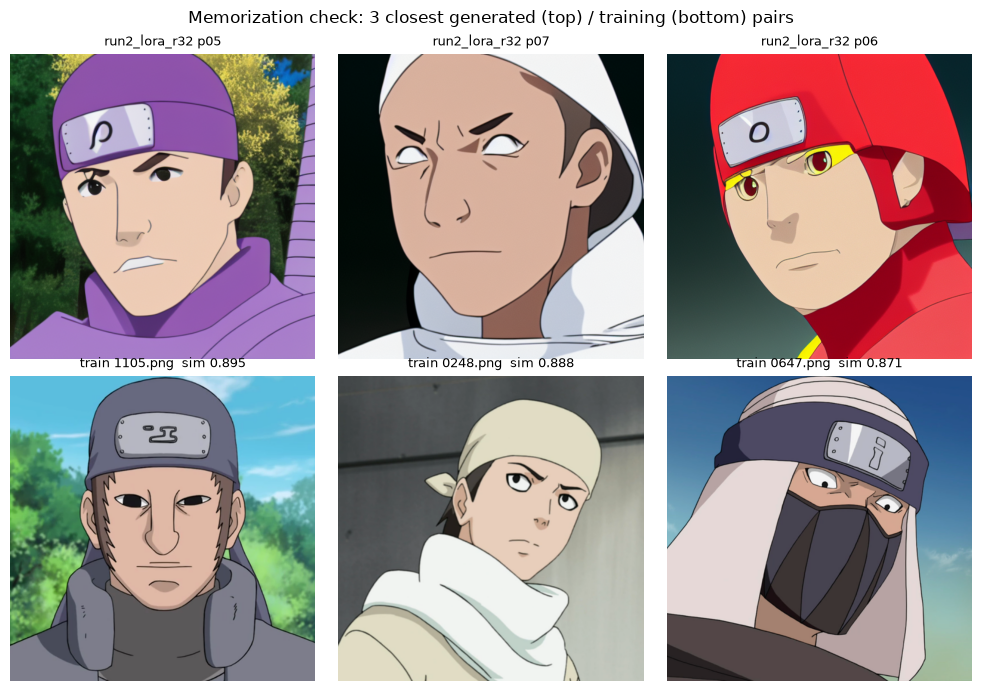

In [18]:
train_paths = [TRAIN_DIR / t["file_name"] for t in train_meta]
train_emb = image_emb(train_paths)
mem_rows = []
for name in ["base", FINAL_RUN]:
    g = gen[(gen.model == name) & (gen.type == "in_domain") & (gen.seed == 0)]
    assert len(g) == 10, len(g)
    sims = image_emb(list(g.path)) @ train_emb.T
    best, idx = sims.max(dim=1)
    for (_, r), s, i in zip(g.iterrows(), best.tolist(), idx.tolist()):
        mem_rows.append({"model": name, "id": r.id, "file": r.file, "nearest_train": train_meta[i]["file_name"],
                         "nearest_train_caption": train_meta[i]["text"], "clip_sim": round(s, 4)})
mem = pd.DataFrame(mem_rows); mem.to_csv(OUT_DIR / "memorization.csv", index=False)
print(mem.groupby("model").clip_sim.agg(["mean", "max"]).round(3))
top3 = mem[mem.model == FINAL_RUN].nlargest(3, "clip_sim")
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for c, r in enumerate(top3.itertuples()):
    axes[0, c].imshow(Image.open(gen.set_index("file").path[r.file])); axes[0, c].set_title(f"{FINAL_RUN} {r.id}", fontsize=9)
    axes[1, c].imshow(Image.open(TRAIN_DIR / r.nearest_train)); axes[1, c].set_title(f"train {r.nearest_train}  sim {r.clip_sim:.3f}", fontsize=9)
for a in axes.flat: a.axis("off")
plt.suptitle("Memorization check: 3 closest generated (top) / training (bottom) pairs"); plt.tight_layout()
plt.savefig(OUT_DIR / "memorization_top3.png", dpi=80); plt.show()

## Failure modes (evidence)
1. **Composition collapse:** prompts that ask for two or three characters. The seed-0 and seed-1 images of the
   compositional prompts are shown for every model (red frame = NSFW-flagged, audited checker-off copy).
2. **Close-up framing, which also trips the safety checker:** the LoRAs often fill the frame with one face even
   when the prompt describes a scene. Measured with CLIP zero-shot (ViT-L/14): an image counts as a close-up when it
   is closer to "a close-up portrait of a face filling the frame" than to "a full-body character standing in a
   scene". Rates are given for the training images, each model's 122 test-caption images, and for flagged vs
   non-flagged LoRA images.
3. **Checked and rejected:** a dark vertical bar at the image edge was seen in the LoRA check grid after training.
   Measured here (at least 8 dark, flat columns at the left or right edge). If base shows it as often as the LoRAs,
   it is a base-model artifact, not something the LoRA learned.

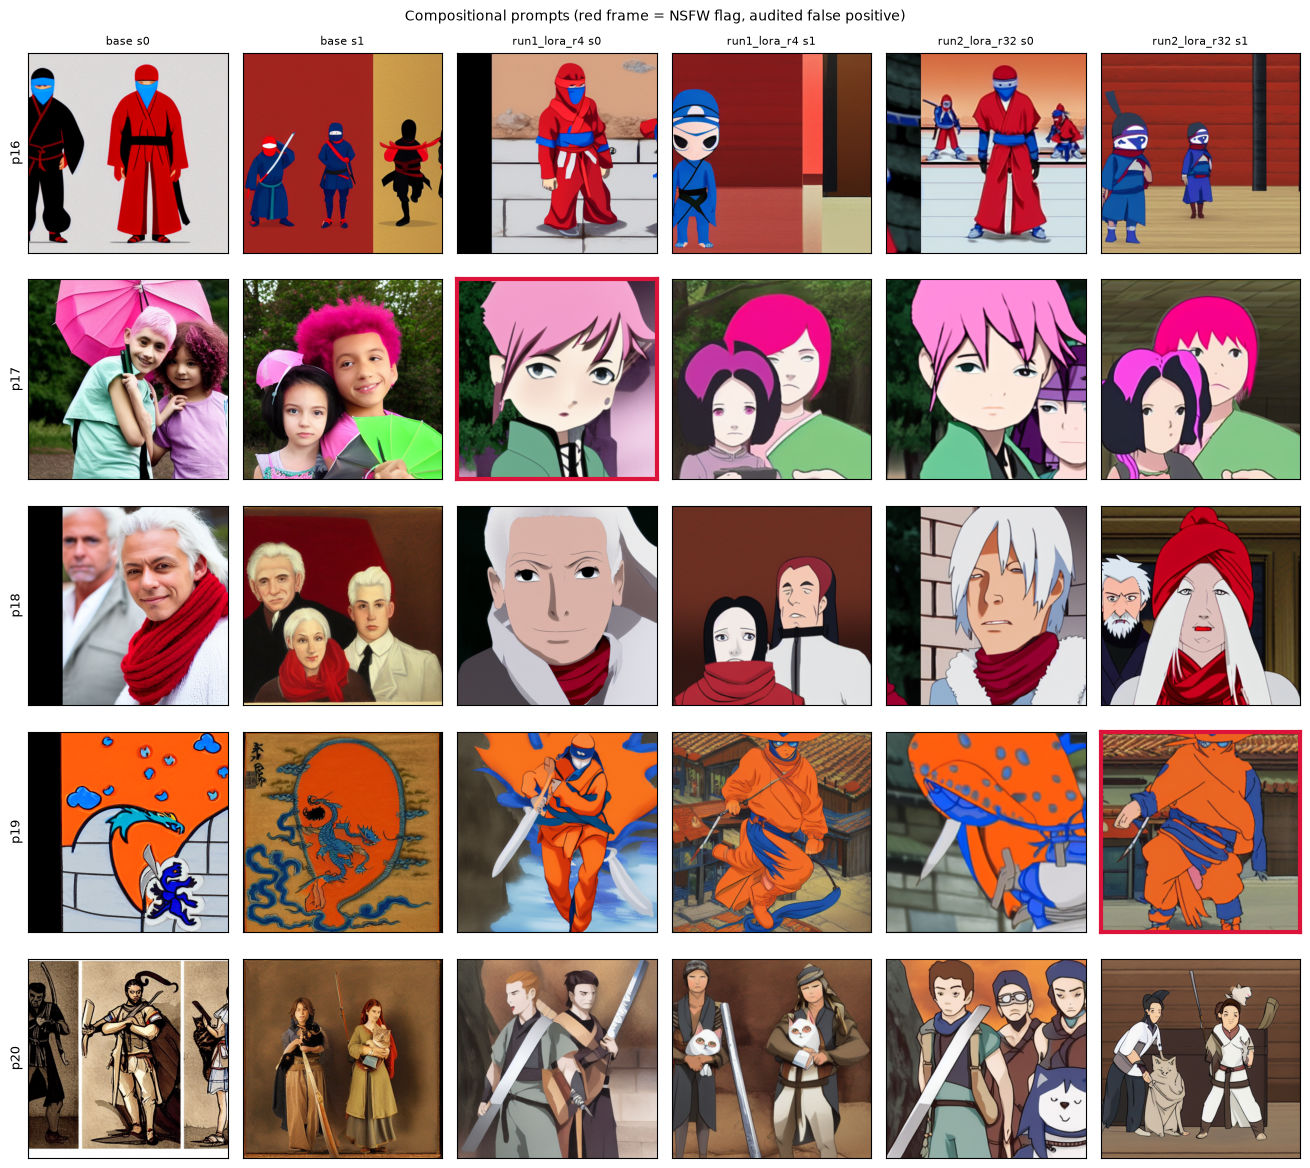

p16 two ninja characters standing side by side, one wearing red and one wearing blue
p17 a girl with pink hair holding a green umbrella next to a boy with black hair
p18 a man with white hair standing to the left of a woman with a red scarf
p19 a ninja in an orange jacket riding a blue dragon above a village
p20 three characters: one holding a sword, one holding a book and one holding a cat
Share of close-up images: {'train_images': 0.087, 'base_test_captions': 0.443, 'run1_lora_r4_test_captions': 0.107, 'run1_lora_r4_flagged': 0.091, 'run1_lora_r4_not_flagged': 0.115, 'run2_lora_r32_test_captions': 0.049, 'run2_lora_r32_flagged': 0.025, 'run2_lora_r32_not_flagged': 0.061}


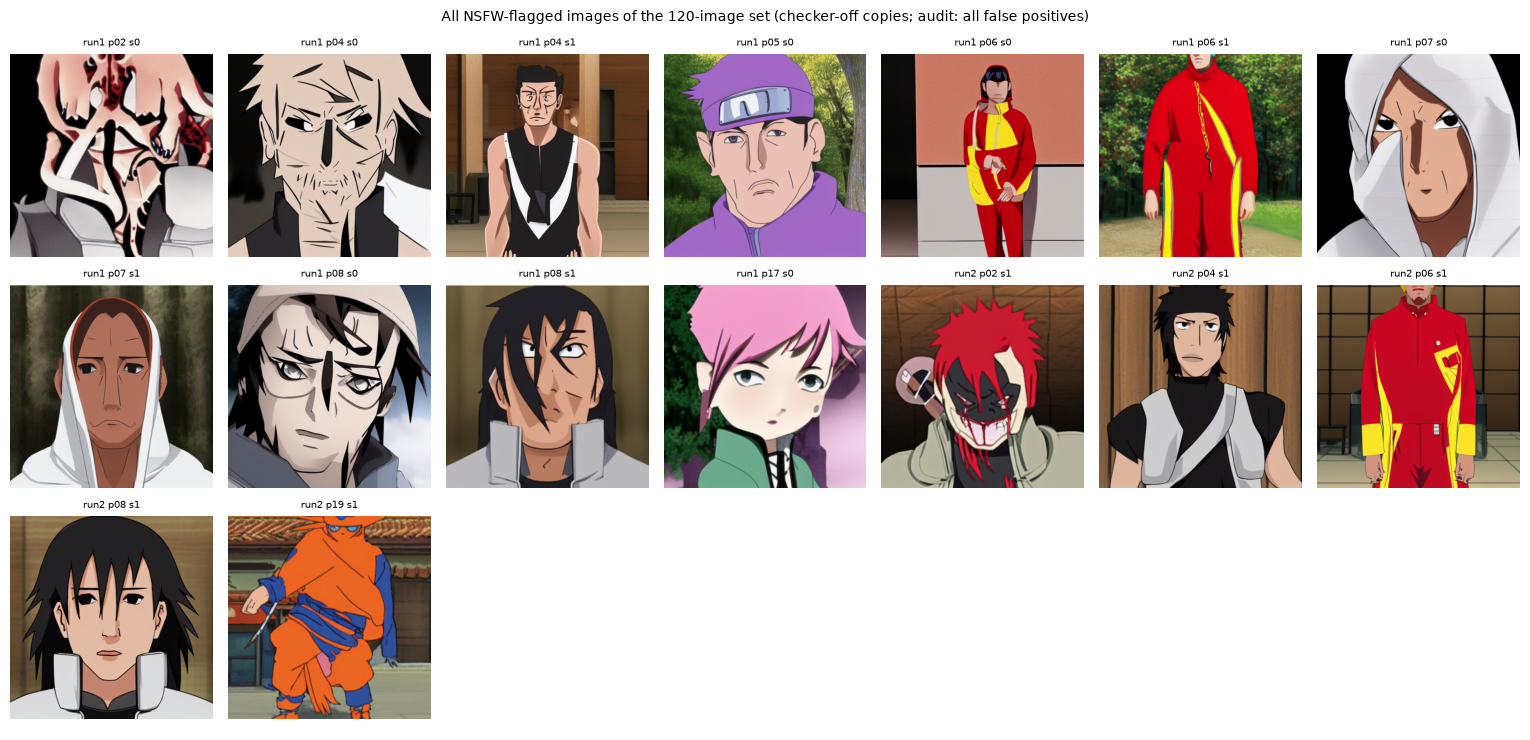

Share of images with a dark edge bar: {'train_images': 0.054, 'base': 0.175, 'base_test_captions': 0.016, 'run1_lora_r4': 0.025, 'run1_lora_r4_test_captions': 0.008, 'run2_lora_r32': 0.05, 'run2_lora_r32_test_captions': 0.008}


253

In [19]:
comp_ids = list(prompts[prompts.type == "compositional"].id)
fig, axes = plt.subplots(len(comp_ids), 2 * len(MODELS), figsize=(2.2 * 2 * len(MODELS), 2.4 * len(comp_ids)), squeeze=False)
for r, pid in enumerate(comp_ids):
    for c, (name, s) in enumerate([(m, s) for m in MODELS for s in SEEDS]):
        g = gen[(gen.model == name) & (gen.id == pid) & (gen.seed == s)].iloc[0]
        ax = axes[r, c]; ax.imshow(Image.open(g.path)); ax.set_xticks([]); ax.set_yticks([])
        if g.nsfw_flag:
            for sp in ax.spines.values(): sp.set_edgecolor("crimson"); sp.set_linewidth(3)
        if r == 0: ax.set_title(f"{name} s{s}", fontsize=8)
    axes[r, 0].set_ylabel(pid, fontsize=9)
plt.suptitle("Compositional prompts (red frame = NSFW flag, audited false positive)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "failure_compositional.png", dpi=60); plt.show()
for pid in comp_ids: print(pid, prompts[prompts.id == pid].prompt.iloc[0])

# Close-up framing (CLIP zero-shot)
framing = text_emb(["a close-up portrait of a face filling the frame", "a full-body character standing in a scene"])
def closeup(emb): return ((emb @ framing.T).argmax(-1) == 0).numpy()
close = {"train_images": float(closeup(train_emb).mean())}
if EXTENDED_KID:
    gen_kid["closeup"] = closeup(image_emb(list(gen_kid.path)))
    for name in MODELS:
        k = gen_kid[gen_kid.model == name]
        close[f"{name}_test_captions"] = float(k.closeup.mean())
        if k.nsfw_flag.any():
            close[f"{name}_flagged"] = float(k[k.nsfw_flag].closeup.mean())
            close[f"{name}_not_flagged"] = float(k[~k.nsfw_flag].closeup.mean())
print("Share of close-up images:", {k: round(v, 3) for k, v in close.items()})
(OUT_DIR / "closeup_rates.json").write_text(json.dumps(close, indent=1))
fl = gen[gen.nsfw_flag].sort_values(["model", "id", "seed"])
if len(fl):
    cols = 7; rows_n = -(-len(fl) // cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.2 * cols, 2.5 * rows_n), squeeze=False)
    for a in axes.flat: a.axis("off")
    for a, r in zip(axes.flat, fl.itertuples()):
        a.imshow(Image.open(r.path)); a.set_title(f"{r.model.split('_')[0]} {r.id} s{r.seed}", fontsize=7)
    plt.suptitle("All NSFW-flagged images of the 120-image set (checker-off copies; audit: all false positives)", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT_DIR / "failure_flagged_closeups.png", dpi=60); plt.show()

def edge_bar(path, min_px=8):
    """True if at least min_px columns at the left or right edge are each dark and flat (mean < 30, std < 20)."""
    g = np.asarray(Image.open(path).convert("L"), dtype=np.float32)
    dark = (g.mean(axis=0) < 30) & (g.std(axis=0) < 20)
    run = lambda cols: next((k for k, d in enumerate(cols) if not d), len(cols))
    return max(run(dark), run(dark[::-1])) >= min_px
bar_rates = {"train_images": float(np.mean([edge_bar(p) for p in train_paths]))}
for name in MODELS:
    bar_rates[name] = float(np.mean([edge_bar(p) for p in gen[gen.model == name].path]))
    if EXTENDED_KID:
        bar_rates[f"{name}_test_captions"] = float(np.mean([edge_bar(p) for p in gen_kid[gen_kid.model == name].path]))
print("Share of images with a dark edge bar:", {k: round(v, 3) for k, v in bar_rates.items()})
(OUT_DIR / "edge_bar_rates.json").write_text(json.dumps(bar_rates, indent=1))

## 2.4 Human evaluation pack: 25 blinded pairs (final run vs base)
25 of the 40 (prompt, seed) pairs are drawn with seed 266 (flagged images shown as their audited checker-off copy);
left/right is randomized per pair. `pairs.html` shows
the pairs as A/B with no model names. Each rater fills a copy of `rater_TEMPLATE.csv` (A or B for **style** =
looks like the Naruto anime, and **prompt match**) and saves it as `outputs/p2/human_eval/rater_<name>.csv`.
At least 3 raters: both members and one person outside the team. The answer key is in `key.csv`.

In [20]:
HE_DIR = OUT_DIR / "human_eval"; HE_DIR.mkdir(exist_ok=True)
if (HE_DIR / "key.csv").exists():   # never rebuild the pack once raters may have it: the key must stay the same
    _k = pd.read_csv(HE_DIR / "key.csv")
    assert set(_k.A) | set(_k.B) == {"base", FINAL_RUN}, (f"key.csv compares base with {set(_k.A) - {'base'}}, but "
        f"FINAL_RUN is {FINAL_RUN}. Set FINAL_RUN by hand, or delete human_eval/ before any rater has started.")
rng = np.random.default_rng(SEED)
cands = [(r.id, s) for r in prompts.itertuples() for s in SEEDS]       # all 40 pairs (v3 left 9 flagged pairs out)
picked = [cands[i] for i in sorted(rng.choice(len(cands), 25, replace=False))]
order = rng.permutation(25)
key_rows, html = [], ["<!doctype html><meta charset='utf-8'><title>Image pairs</title>",
                      "<style>body{font-family:sans-serif;max-width:900px;margin:auto;padding:16px}"
                      ".p{margin:28px 0;border-top:1px solid #ccc;padding-top:12px}.p img{width:49%}</style>",
                      "<h1>Which image is better?</h1><p>For each pair answer two questions with A or B: "
                      "<b>style</b> (which looks more like the Naruto anime) and <b>prompt</b> (which matches the text better). "
                      "Write the answers in your copy of rater_TEMPLATE.csv.</p>"]
def b64(path):
    buf = io.BytesIO(); Image.open(path).convert("RGB").resize((384, 384)).save(buf, "JPEG", quality=85)
    return base64.b64encode(buf.getvalue()).decode()
for n, k in enumerate(order, start=1):
    pid, s = picked[k]
    files = {m: gen[(gen.model == m) & (gen.id == pid) & (gen.seed == s)].path.iloc[0] for m in ("base", FINAL_RUN)}
    left = "base" if rng.random() < 0.5 else FINAL_RUN; right = FINAL_RUN if left == "base" else "base"
    key_rows.append({"pair": n, "prompt_id": pid, "seed": s, "A": left, "B": right})
    text = prompts[prompts.id == pid].prompt.iloc[0]
    html.append(f"<div class='p'><h3>Pair {n}</h3><p>{text}</p><b>A</b> <img src='data:image/jpeg;base64,{b64(files[left])}'> "
                f"<img src='data:image/jpeg;base64,{b64(files[right])}'> <b>B</b></div>")
assert not (HE_DIR / "key.csv").exists() or pd.read_csv(HE_DIR / "key.csv").equals(pd.DataFrame(key_rows)), \
    "the rebuilt pairs differ from key.csv"
pd.DataFrame(key_rows).to_csv(HE_DIR / "key.csv", index=False)
pd.DataFrame({"pair": range(1, 26), "style_better": "", "prompt_better": ""}).to_csv(HE_DIR / "rater_TEMPLATE.csv", index=False)
(HE_DIR / "pairs.html").write_text("\n".join(html))
print("Wrote", HE_DIR / "pairs.html", "| A is the final run in", sum(r["A"] == FINAL_RUN for r in key_rows), "of 25 pairs",
      "| pairs with a flagged image:", sum((FINAL_RUN, r["prompt_id"], r["seed"]) in set(zip(gen[gen.nsfw_flag].model, gen[gen.nsfw_flag].id, gen[gen.nsfw_flag].seed)) for r in key_rows))

Wrote C:\Users\centhur1.ADS-A51-840-12\Desktop\LAB2\DATA266_Lab2_Part2_VSCode\outputs\p2\human_eval\pairs.html | A is the final run in 12 of 25 pairs | pairs with a flagged image: 3


In [21]:
# Human evaluation results (runs again after the rater files are added)
key = pd.read_csv(HE_DIR / "key.csv")
raters = sorted(p for p in HE_DIR.glob("rater_*.csv") if p.name != "rater_TEMPLATE.csv")
if not raters:
    print("No rater files yet. Add outputs/p2/human_eval/rater_<name>.csv (at least 3) and run this cell again.")
else:
    he = []
    for p in raters:
        r = pd.read_csv(p).merge(key, on="pair")
        for q in ("style_better", "prompt_better"):
            ans = r[q].astype(str).str.strip().str.upper()
            win = np.where(ans == "A", r["A"], np.where(ans == "B", r["B"], None)) == FINAL_RUN
            he.append({"rater": p.stem[6:], "question": q, "answered": int(ans.isin(["A", "B"]).sum()),
                       "final_run_win_rate": round(float(win[ans.isin(["A", "B"])].mean()), 3)})
    he = pd.DataFrame(he); he.to_csv(OUT_DIR / "human_eval_results.csv", index=False)
    print(he.pivot(index="rater", columns="question", values="final_run_win_rate"))
    print("Mean win rate of", FINAL_RUN, "over base:", he.groupby("question").final_run_win_rate.mean().round(3).to_dict())

No rater files yet. Add outputs/p2/human_eval/rater_<name>.csv (at least 3) and run this cell again.


## Upload the 120 images to a Hugging Face dataset
One row per image with `model`, `prompt_id`, `type`, `prompt`, `seed`, the sampler settings, the NSFW flag and
`image_source` (`pipeline`, or `checker_off_audited` for a flagged image: the same sample with the checker off).
The upload replaces the 14 black PNGs of the v2/v3 upload. Needs the Colab secret `HF_TOKEN` (write); **private**.

In [ ]:
import os
from huggingface_hub import get_token

os.environ["HF_TOKEN"] = get_token()
print("HF token detected:", bool(os.environ["HF_TOKEN"]))

In [22]:
token = os.environ.get("HF_TOKEN")
if IN_COLAB and not token:
    try:
        from google.colab import userdata; token = userdata.get("HF_TOKEN")
    except Exception as e:
        print("No HF_TOKEN secret:", repr(e))
if token:
    from huggingface_hub import HfApi
    api = HfApi(token=token); user = api.whoami()["name"]
    repo = f"{user}/data266-lab2-naruto-sd15-generations"
    import shutil
    stage = Path("/content/hf_upload" if IN_COLAB else str(PROJECT_ROOT / "outputs" / "p2_drive" / "hf_upload")); shutil.rmtree(stage, ignore_errors=True); stage.mkdir(parents=True)
    for r in gen.itertuples(): shutil.copy2(r.path, stage / r.file)        # checker-off copy for flagged images
    meta = gen.rename(columns={"file": "file_name", "id": "prompt_id"})[
        ["file_name", "model", "prompt_id", "type", "prompt", "seed", "nsfw_flag", "image_source", "clip_score"]].copy()
    meta["adapter"] = meta.model.map(lambda m: MODELS[m].name if MODELS[m] else "none")
    for k, v in SAMPLER.items(): meta[k] = v
    meta.to_csv(stage / "metadata.csv", index=False)
    api.create_repo(repo, repo_type="dataset", private=True, exist_ok=True)
    info = api.upload_folder(repo_id=repo, repo_type="dataset", folder_path=str(stage),
                             allow_patterns=["*.png", "metadata.csv"],
                             commit_message="v4: 120 images (20 prompts x 2 seeds x 3 models); flagged ones as audited checker-off copies")
    (OUT_DIR / "hf_dataset_link.json").write_text(json.dumps({"url": f"https://huggingface.co/datasets/{repo}",
                                                              "commit": info.oid}, indent=1))
    print("Uploaded to", f"https://huggingface.co/datasets/{repo}")
else:
    print("Not uploaded: add the Colab secret HF_TOKEN and run this cell again.")

Not uploaded: add the Colab secret HF_TOKEN and run this cell again.


In [23]:
# Run finished - release the GPU (Colab)
if IN_COLAB and AUTO_DISCONNECT:
    print("Run complete - disconnecting.")
    runtime.unassign()